# Homework 6 — Decision Trees and Ensemble Learning

**Machine Learning Zoomcamp 2026 · Car fuel-efficiency regression**

The target is `fuel_efficiency_mpg`. This notebook compares a shallow decision
tree, random forests, and XGBoost using validation root mean squared error
(RMSE). Lower RMSE means better predictions in the target's units, miles per gallon.

All models use the full set of available input columns. The four features listed
as answer choices in some questions do not restrict the model's input features.
The held-out test set is not used for training, tuning, or selecting answers.

The notebook already contains executed results. To run it again, install the
dependencies from the accompanying `requirements.txt` and run the cells in order.
If the CSV is absent, it is downloaded automatically from a fixed course commit.
No separate output folder is required.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb
from IPython.display import display
from scipy import sparse
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

get_ipython().run_line_magic('matplotlib', 'inline')
print(f'Python: {platform.python_version()}')
print(f'NumPy: {np.__version__}; pandas: {pd.__version__}')
print(f'scikit-learn: {sklearn.__version__}; XGBoost: {xgb.__version__}')
pd.set_option('display.precision', 6)
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

Python: 3.11.15
NumPy: 2.3.3; pandas: 2.3.2
scikit-learn: 1.7.2; XGBoost: 3.2.0


## 1. Load and prepare the pinned dataset

Missing values are replaced with zero exactly as requested. The CSV checksum
is compared with the course release checksum to prevent using another dataset.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/f890391cf579ddf20decf9c67766b4a27e0b8ae1/cohorts/2026/data/car_fuel_efficiency_2026.csv'
EXPECTED_SHA256 = '00a5cab178a8b7cd6e9157ee71dabc236ba7f20b1832336d358b07af14ba431f'
data_path = Path('car_fuel_efficiency_2026.csv')
if not data_path.exists():
    data_path.write_bytes(urllib.request.urlopen(DATA_URL, timeout=60).read())

actual_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert actual_sha256 == EXPECTED_SHA256, 'This CSV differs from the pinned 2026 release.'
df = pd.read_csv(data_path)
print('Shape:', df.shape)
print('Missing values before filling:')
print(df.isna().sum().to_string())
assert df['fuel_efficiency_mpg'].notna().all()
df = df.fillna(0)
assert not df.isna().any().any()
display(df.head())

Shape: (10000, 11)
Missing values before filling:
model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0


,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,0.0,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,0.0,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [3]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

target = 'fuel_efficiency_mpg'
features = df.columns.drop(target).tolist()
y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()

assert (len(df_train), len(df_val), len(df_test)) == (6000, 2000, 2000)
assert set(df_train.index).isdisjoint(df_val.index)
assert set(df_full_train.index).isdisjoint(df_test.index)

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))
feature_names = dv.get_feature_names_out()
assert sparse.issparse(X_train) and sparse.issparse(X_val)
assert target not in feature_names

print(f'Train: {len(df_train)} | Validation: {len(df_val)} | Test: {len(df_test)}')
print('Training matrix:', X_train.shape)
print('Original input columns:', features)
print('Encoded columns:', feature_names.tolist())

Train: 6000 | Validation: 2000 | Test: 2000
Training matrix: (6000, 16)
Original input columns: ['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors', 'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight', 'acceleration']
Encoded columns: ['acceleration', 'drivetrain=All-wheel drive', 'drivetrain=Front-wheel drive', 'drivetrain=Rear-wheel drive', 'engine_displacement', 'fuel_type=Diesel', 'fuel_type=Gasoline', 'fuel_type=Hybrid', 'horsepower', 'model_year', 'num_cylinders', 'num_doors', 'origin=Asia', 'origin=Europe', 'origin=USA', 'vehicle_weight']


## Question 1 — Which feature does a depth-one tree use?

A tree with `max_depth=1` makes one split. Read its root feature from
`tree_.feature[0]` and map a categorical one-hot feature back to its original
column name. For example, `origin=USA` corresponds to `origin`.

In [4]:
tree = DecisionTreeRegressor(max_depth=1, random_state=1)
tree.fit(X_train, y_train)
root_feature = feature_names[tree.tree_.feature[0]]
q1 = root_feature.split('=', 1)[0]
print(export_text(tree, feature_names=feature_names.tolist()))
print('Encoded root feature:', root_feature)
print('Answer Q1:', q1)

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]

Encoded root feature: model_year
Answer Q1: model_year


## Question 2 — Random forest validation RMSE

Train ten trees with `random_state=1`. Calculate

$$
\mathrm{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

on validation data.

The assignment allows the closest numerical option. The function below applies
that rule, choosing the higher option for an exact midpoint.

In [5]:
def closest_option(value, options):
    distances = {option: abs(float(value) - option) for option in options}
    minimum = min(distances.values())
    tied = [option for option in options
            if np.isclose(distances[option], minimum, rtol=0, atol=1e-12)]
    return max(tied)

rf10 = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf10.fit(X_train, y_train)
q2_rmse = float(root_mean_squared_error(y_val, rf10.predict(X_val)))
q2 = closest_option(q2_rmse, [0.1837, 1.837, 18.37, 183.7])
print(f'Calculated validation RMSE: {q2_rmse:.9f}')
print('Answer Q2:', q2)

Calculated validation RMSE: 1.837054055
Answer Q2: 1.837


## Question 3 — Select the number of trees

Compare exactly `n_estimators = [10, 50, 100, 150]`, keeping `random_state=1`.
Select the lowest validation RMSE after rounding to three decimals. If rounded
scores tie, this notebook selects the smaller forest; the full scores remain visible.

,n_estimators,validation_rmse,rmse_3dp
0,10,1.837054,1.837
1,50,1.771567,1.772
2,100,1.768136,1.768
3,150,1.768804,1.769


Answer Q3: 100


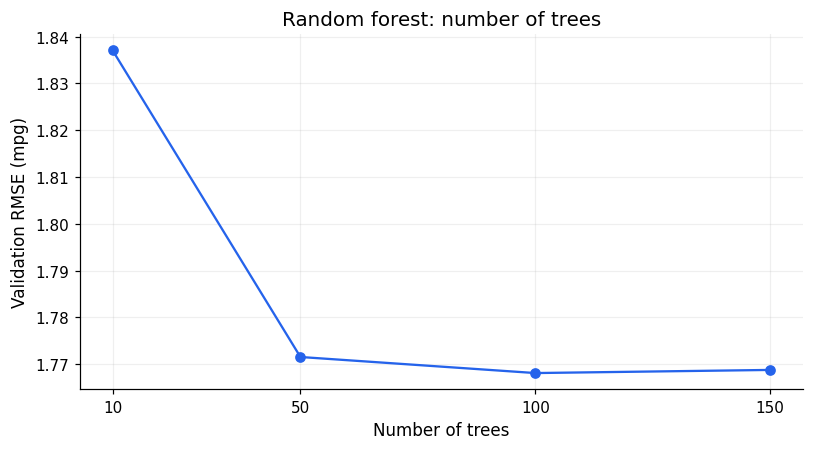

In [6]:
n_values = [10, 50, 100, 150]
size_rows = []
for n in n_values:
    if n == 10:
        score = q2_rmse  # Reuse the identical model from Q2.
    else:
        forest = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
        forest.fit(X_train, y_train)
        score = float(root_mean_squared_error(y_val, forest.predict(X_val)))
    size_rows.append({'n_estimators': n, 'validation_rmse': score, 'rmse_3dp': round(score, 3)})

size_scores = pd.DataFrame(size_rows)
q3 = int(size_scores.sort_values(['rmse_3dp', 'n_estimators']).iloc[0]['n_estimators'])
display(size_scores)
print('Answer Q3:', q3)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(size_scores['n_estimators'], size_scores['validation_rmse'], marker='o', color='#2563eb')
ax.set(xlabel='Number of trees', ylabel='Validation RMSE (mpg)',
       title='Random forest: number of trees', xticks=n_values)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Question 4 — Select max_depth by mean RMSE

For each depth in `[10, 15, 20, 25]`, train four forests with the same tree
counts from Q3. Average their four validation RMSE values, then choose the depth
with the smallest mean. This is an average across forest sizes, not cross-validation.

n_estimators,10,50,100,150
max_depth,,,,
10,1.783693,1.748567,1.744839,1.744520
15,1.829892,1.771141,1.767874,1.766904
20,1.841031,1.773109,1.769152,1.769676
25,1.836775,1.772108,1.768403,1.767983


,max_depth,mean_validation_rmse
0,10,1.755405
1,15,1.783953
2,20,1.788242
3,25,1.786317


Answer Q4: 10


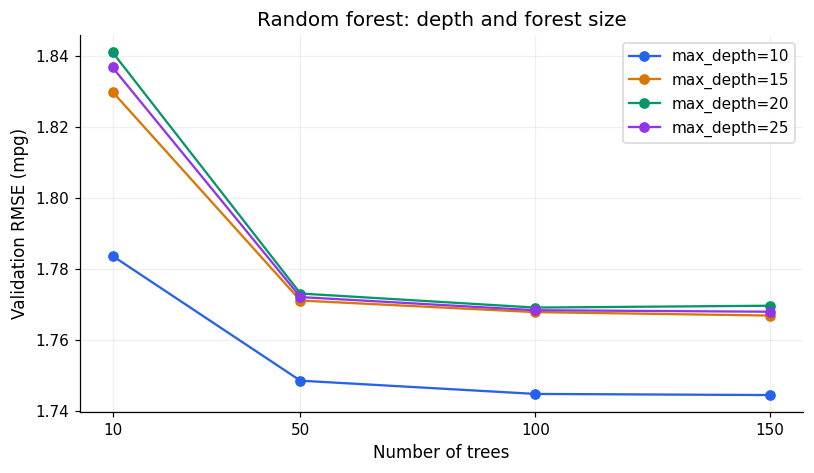

In [7]:
depth_values = [10, 15, 20, 25]
depth_rows = []
q5_forest = None
for depth in depth_values:
    for n in n_values:
        forest = RandomForestRegressor(
            n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1
        )
        forest.fit(X_train, y_train)
        score = float(root_mean_squared_error(y_val, forest.predict(X_val)))
        depth_rows.append({'max_depth': depth, 'n_estimators': n, 'validation_rmse': score})
        if depth == 20 and n == 10:
            q5_forest = forest  # Reuse the exact model requested in Q5.

depth_scores = pd.DataFrame(depth_rows)
depth_means = depth_scores.groupby('max_depth', as_index=False)['validation_rmse'].mean()
depth_means = depth_means.rename(columns={'validation_rmse': 'mean_validation_rmse'})
q4 = int(depth_means.sort_values(['mean_validation_rmse', 'max_depth']).iloc[0]['max_depth'])
display(depth_scores.pivot(index='max_depth', columns='n_estimators', values='validation_rmse'))
display(depth_means)
print('Answer Q4:', q4)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
colors = ['#2563eb', '#d97706', '#059669', '#9333ea']
for depth, color in zip(depth_values, colors):
    subset = depth_scores[depth_scores['max_depth'] == depth]
    ax.plot(subset['n_estimators'], subset['validation_rmse'], marker='o', color=color, label=f'max_depth={depth}')
ax.set(xlabel='Number of trees', ylabel='Validation RMSE (mpg)',
       title='Random forest: depth and forest size', xticks=n_values)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Question 5 — Feature importance

Use the forest with `n_estimators=10`, `max_depth=20`, and `random_state=1`.
Its impurity-based importance measures the total weighted reduction in squared
error attributed to each encoded feature. Sum one-hot importances back to the
original columns, and compare the four requested candidates.

These importances describe the fitted model, not causal effects. Correlated
inputs can share importance, and continuous features can receive an advantage
because they offer many possible split points.

,original_feature,importance
0,model_year,0.296001
1,vehicle_weight,0.203879
2,fuel_type,0.193551
3,horsepower,0.078017
4,engine_displacement,0.061005
5,acceleration,0.055201
6,origin,0.052040
7,drivetrain,0.033608
8,num_doors,0.019415
9,num_cylinders,0.007284


Answer Q5: vehicle_weight


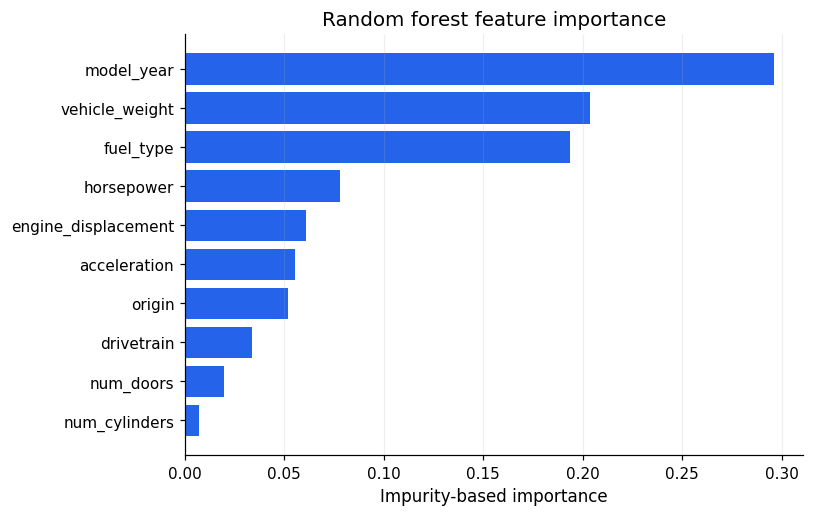

In [8]:
assert q5_forest is not None
encoded_importance = pd.DataFrame({
    'encoded_feature': feature_names,
    'importance': q5_forest.feature_importances_,
})
encoded_importance['original_feature'] = encoded_importance['encoded_feature'].str.split('=', n=1).str[0]
original_importance = encoded_importance.groupby('original_feature', as_index=False)['importance'].sum()
original_importance = original_importance.sort_values('importance', ascending=False)
assert np.isclose(original_importance['importance'].sum(), 1.0)

candidates = ['vehicle_weight', 'horsepower', 'acceleration', 'engine_displacement']
candidate_importance = original_importance[original_importance['original_feature'].isin(candidates)]
q5 = candidate_importance.iloc[0]['original_feature']
display(original_importance.reset_index(drop=True))
print('Answer Q5:', q5)

plot_data = original_importance.sort_values('importance')
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.barh(plot_data['original_feature'], plot_data['importance'], color='#2563eb')
ax.set(xlabel='Impurity-based importance', title='Random forest feature importance')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
plt.show()

## Question 6 — XGBoost learning rate

Create sparse `DMatrix` objects and a train/validation watchlist. Train **100
rounds** for each `eta` value, using all other parameters exactly as stated.
There is no early stopping: compare validation RMSE after round 100. The printed
training log uses zero-based indices, so iteration `[99]` is the 100th round.

A sparse `DMatrix` treats absent entries as missing. Here it is built directly
from the `DictVectorizer(sparse=True)` matrices required by the homework.

eta = 0.3
[0]	train-rmse:2.40653	val-rmse:2.46782
[25]	train-rmse:1.35837	val-rmse:1.74359
[50]	train-rmse:1.18645	val-rmse:1.77517
[75]	train-rmse:1.02727	val-rmse:1.80682
[99]	train-rmse:0.90106	val-rmse:1.82646
eta = 0.1
[0]	train-rmse:2.74739	val-rmse:2.78635
[25]	train-rmse:1.50918	val-rmse:1.72751
[50]	train-rmse:1.40368	val-rmse:1.71358
[75]	train-rmse:1.35099	val-rmse:1.72057
[99]	train-rmse:1.31192	val-rmse:1.72481


,eta,validation_rmse_round_100,best_observed_validation_rmse,best_observed_round
0,0.3,1.826458,1.732048,11
1,0.1,1.724810,1.712171,40


Answer Q6: 0.1


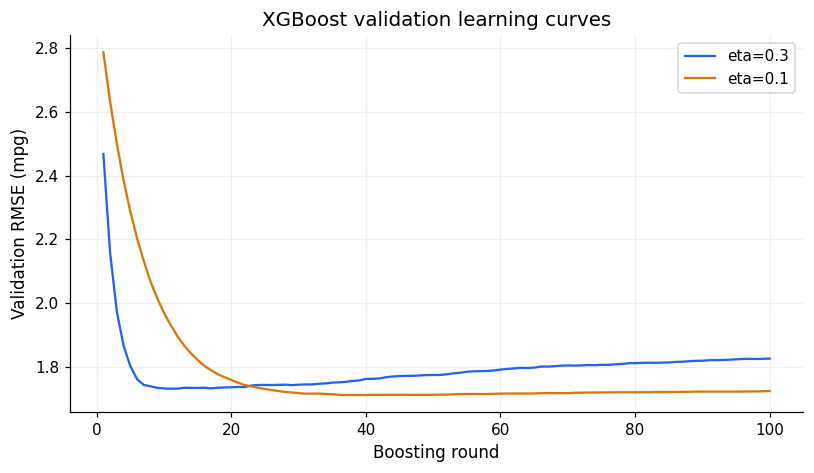

In [9]:
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names.tolist())
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names.tolist())
watchlist = [(dtrain, 'train'), (dval, 'val')]

learning_curves = {}
xgb_rows = []
for eta in [0.3, 0.1]:
    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'reg:squarederror',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1,
    }
    history = {}
    print(f'eta = {eta}')
    booster = xgb.train(
        xgb_params, dtrain, num_boost_round=100,
        evals=watchlist, evals_result=history, verbose_eval=25,
    )
    score = float(root_mean_squared_error(y_val, booster.predict(dval)))
    assert np.isclose(score, history['val']['rmse'][-1], atol=1e-6)
    assert len(history['val']['rmse']) == 100
    learning_curves[eta] = history
    xgb_rows.append({
        'eta': eta,
        'validation_rmse_round_100': score,
        'best_observed_validation_rmse': min(history['val']['rmse']),
        'best_observed_round': int(np.argmin(history['val']['rmse']) + 1),
    })

xgb_scores = pd.DataFrame(xgb_rows)
scores_by_eta = xgb_scores.set_index('eta')['validation_rmse_round_100']
if scores_by_eta.loc[0.3] == scores_by_eta.loc[0.1]:
    q6 = 'Both give equal value'
else:
    q6 = float(scores_by_eta.idxmin())
display(xgb_scores)
print('Answer Q6:', q6)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
for eta, color in [(0.3, '#2563eb'), (0.1, '#d97706')]:
    ax.plot(np.arange(1, 101), learning_curves[eta]['val']['rmse'], color=color, label=f'eta={eta}')
ax.set(xlabel='Boosting round', ylabel='Validation RMSE (mpg)',
       title='XGBoost validation learning curves')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Answers

The table below contains the selected options computed above. Q2 also reports
the measured RMSE so that the course's closest-option rule is explicit.

In [10]:
answers = {
    'Q1': q1,
    'Q2': q2,
    'Q3': q3,
    'Q4': q4,
    'Q5': q5,
    'Q6': q6,
}
answer_table = pd.DataFrame({
    'Question': list(answers),
    'Selected answer': list(answers.values()),
})
display(answer_table)
print(f'Q2 calculated RMSE = {q2_rmse:.9f}; closest offered option = {q2}')
print(json.dumps(answers, indent=2))

,Question,Selected answer
0,Q1,model_year
1,Q2,1.837
2,Q3,100
3,Q4,10
4,Q5,vehicle_weight
5,Q6,0.1


Q2 calculated RMSE = 1.837054055; closest offered option = 1.837
{
  "Q1": "model_year",
  "Q2": 1.837,
  "Q3": 100,
  "Q4": 10,
  "Q5": "vehicle_weight",
  "Q6": 0.1
}


## Main takeaways

- A shallow decision tree is easy to inspect, but a single split has limited capacity.
- Random forests average many trees. Increasing the number of trees can improve
  stability, although the validation gain can become small.
- Tree depth changes model capacity. In Q4 the selected depth is based on the mean
  error across four forest sizes.
- A lower XGBoost learning rate changes how quickly the model learns; its effect
  must be evaluated with the specified number of boosting rounds.

Source: [2026 homework](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/06-trees/homework.md).
Dataset: [fixed release commit](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/f890391cf579ddf20decf9c67766b4a27e0b8ae1/cohorts/2026/data/car_fuel_efficiency_2026.csv).